# Entrenamiento del modelo · Predicción de `happiness_score`

**Entrenamiento del modelo:** entrena el modelo, lo evalúa **una sola vez** con el 30 % de prueba y guarda los artefactos que usará el consumer.

Decisiones tomadas en `eda.ipynb` (con la evidencia allí):
- **Regresión lineal** (el bosque aleatorio no mejora de forma significativa).
- Variables: `gdp`, `family`, `health`, `freedom`, `corruption` estandarizadas. Se descarta `generosity`.
- `year` como **categoría (one-hot)**, con 2015 como año base: cada reporte anual tiene su propio nivel base.
- Un año fuera de 2015-2019 **no** se predice en silencio: el codificador lanza un error (el consumer lo marcará como `PREDICTION_ERROR`).

**Artefactos que genera:** `models/model.pkl`, `models/metrics.json` y `data/streaming/happiness_test.csv` (el 30 % de prueba, que es lo que transmite el producer).

## 0. Configuración

In [1]:
import json
import platform

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RepeatedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from happiness_etl.config import (
    COUNTRY, METRICS_FILE, MODEL_FEATURES, MODEL_FILE, RANDOM_STATE, STREAMING_FILE,
    TARGET, TEST_SIZE, YEAR, YEARS,
)
from happiness_etl.load import read_processed

pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid")
MODEL_FEATURES = list(MODEL_FEATURES)

## 1. Datos y partición
Misma partición que el EDA (70/30, estratificada por año, semilla fija), así lo que se decidió con el entrenamiento nunca vio el conjunto de prueba.

In [2]:
datos = read_processed()
train, test = train_test_split(datos, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=datos[YEAR])
train = train.reset_index(drop=True)
test = test.sort_values([YEAR, COUNTRY]).reset_index(drop=True)

print(f"total={len(datos)}  train={len(train)}  test={len(test)}")
pd.DataFrame({"train": train[YEAR].value_counts().sort_index(), "test": test[YEAR].value_counts().sort_index()})

total=782  train=547  test=235


,train,test
year,,
2015,111,47
2016,110,47
2017,108,47
2018,109,47
2019,109,47


## 2. Pipeline de scikit-learn
Todo el preprocesamiento va **dentro** del pipeline: así el consumer solo carga un archivo y llama a `predict`, y en validación cruzada el escalado se ajusta en cada pliegue sin mirar el pliegue de validación.

- `StandardScaler` sobre las 5 variables numéricas (columnas elegidas por nombre; el orden de llegada no importa).
- `OneHotEncoder` sobre `year` con categorías fijas `2015-2019`, `drop="first"` y `handle_unknown="error"`.
- Las demás columnas (`country`, etc.) se descartan: el país no es una variable del modelo.

In [3]:
def build_pipeline():
    preprocesamiento = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), MODEL_FEATURES),
            ("year", OneHotEncoder(categories=[list(YEARS)], drop="first", handle_unknown="error", sparse_output=False), [YEAR]),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    return Pipeline([("prep", preprocesamiento), ("model", LinearRegression())])


X_cols = MODEL_FEATURES + [YEAR]
pipe = build_pipeline().fit(train[X_cols], train[TARGET])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['gdp','family','health','freedom','corruption','year']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('year', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature

### 2.1 Coeficientes
Con variables estandarizadas, cada coeficiente es el cambio esperado del puntaje por una desviación estándar de la variable. Los de `year_*` son el desplazamiento respecto a 2015.

In [4]:
nombres = pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(pipe.named_steps["model"].coef_, index=nombres, name="coeficiente")
print(f"intercepto = {pipe.named_steps['model'].intercept_:.3f}")
coefs.to_frame().round(3)

intercepto = 5.492


,coeficiente
gdp,0.332
family,0.379
health,0.236
freedom,0.259
corruption,0.075
year_2016,0.359
year_2017,-0.203
year_2018,-0.277
year_2019,-0.282


## 3. Estabilidad en entrenamiento (validación cruzada)
Referencia del error esperado **antes** de abrir la prueba: RMSE de validación cruzada 5x3 solo con el entrenamiento. Si la prueba da algo parecido, no hay sobreajuste.

In [5]:
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
rmse_cv = -cross_val_score(build_pipeline(), train[X_cols], train[TARGET], cv=cv, scoring="neg_root_mean_squared_error")
mae_cv = -cross_val_score(build_pipeline(), train[X_cols], train[TARGET], cv=cv, scoring="neg_mean_absolute_error")
print(f"RMSE CV = {rmse_cv.mean():.3f} (± {rmse_cv.std():.3f})   MAE CV = {mae_cv.mean():.3f} (± {mae_cv.std():.3f})")

RMSE CV = 0.530 (± 0.041)   MAE CV = 0.412 (± 0.030)


## 4. Evaluación en prueba (se usa una sola vez)
Se compara con una referencia trivial (el puntaje promedio del año en entrenamiento) para saber cuánto aportan las variables.

In [6]:
def metricas(y_real, y_pred):
    return {
        "mae": mean_absolute_error(y_real, y_pred),
        "rmse": float(np.sqrt(mean_squared_error(y_real, y_pred))),
        "r2": r2_score(y_real, y_pred),
        "bias": float(np.mean(y_pred - y_real)),  # error con signo (predicho - real)
    }


pred_test = pipe.predict(test[X_cols])
base_test = test[YEAR].map(train.groupby(YEAR)[TARGET].mean())

resultado = pd.DataFrame({
    "modelo": metricas(test[TARGET], pred_test),
    "referencia (promedio del año)": metricas(test[TARGET], base_test),
}).T
resultado

,mae,rmse,r2,bias
modelo,0.421,0.540,0.804,0.039
referencia (promedio del año),1.047,1.239,-0.031,0.111


In [7]:
por_anio = (
    test.assign(pred=pred_test, error=pred_test - test[TARGET])
    .groupby(YEAR)
    .agg(n=("error", "size"), mae=("error", lambda e: e.abs().mean()), bias=("error", "mean"))
)
por_anio

,n,mae,bias
year,,,
2015,47,0.402,-0.019
2016,47,0.424,0.094
2017,47,0.408,0.116
2018,47,0.390,0.026
2019,47,0.482,-0.021


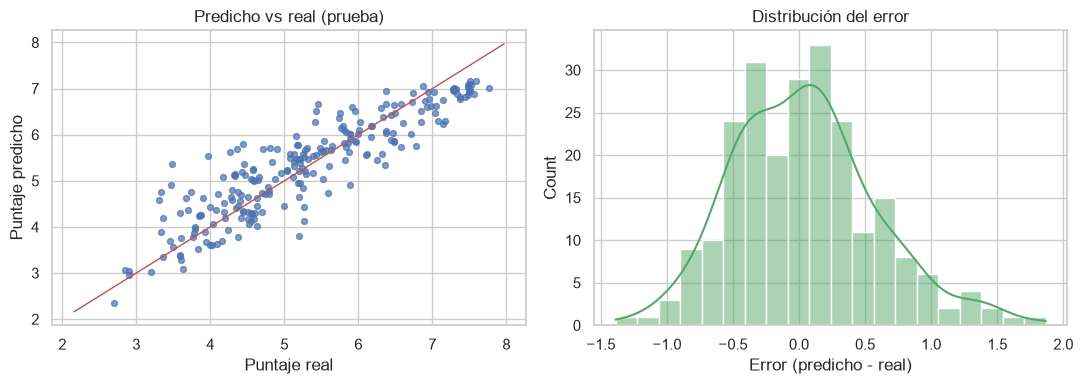

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].scatter(test[TARGET], pred_test, s=18, alpha=0.7, color="#4c72b0")
lim = [min(test[TARGET].min(), pred_test.min()) - 0.2, max(test[TARGET].max(), pred_test.max()) + 0.2]
ejes[0].plot(lim, lim, color="#c44e52", lw=1)
ejes[0].set(xlabel="Puntaje real", ylabel="Puntaje predicho", title="Predicho vs real (prueba)")
sns.histplot(pred_test - test[TARGET], bins=20, kde=True, ax=ejes[1], color="#55a868")
ejes[1].set(xlabel="Error (predicho - real)", title="Distribución del error")
plt.tight_layout()
plt.show()

## 5. Sensibilidad a la imputación de UAE 2018
`corruption` de UAE 2018 era un dato faltante que se interpoló (0.2532, promedio de 2017 y 2019). Hay que comprobar que ese valor inventado no condiciona al modelo ni las métricas, y el efecto depende de en qué conjunto cayó la fila:

- **Si cayó en entrenamiento:** se reentrena sin ella y se comparan coeficientes.
- **Si cayó en prueba:** no influye en el ajuste, pero sí en la evaluación y se transmitirá como evento. Se reportan las métricas con y sin esa fila, y cuánto cambia su predicción dentro del rango plausible de `corruption` (los valores de UAE en 2017 y 2019).

Estas comprobaciones no cambian el modelo: es un análisis de robustez, no un criterio de selección.

In [9]:
UAE = "United Arab Emirates"
imputada = (datos[COUNTRY] == UAE) & (datos[YEAR] == 2018)
fila = datos.loc[imputada].iloc[0]
en_train = ((train[COUNTRY] == UAE) & (train[YEAR] == 2018)).any()
print(f"La fila imputada (corruption = {fila['corruption']:.4f}) está en: {'entrenamiento' if en_train else 'prueba'}")

if en_train:
    # Reentrenar sin la fila y comparar coeficientes
    sin_uae = train.loc[~((train[COUNTRY] == UAE) & (train[YEAR] == 2018))]
    pipe_sin = build_pipeline().fit(sin_uae[X_cols], sin_uae[TARGET])
    comparacion = pd.DataFrame({"con fila": pipe.named_steps["model"].coef_, "sin fila": pipe_sin.named_steps["model"].coef_}, index=nombres)
    comparacion["diferencia"] = comparacion["sin fila"] - comparacion["con fila"]
    display(comparacion.round(4))
else:
    # 1) Métricas de prueba con y sin la fila imputada
    es_uae_test = (test[COUNTRY] == UAE) & (test[YEAR] == 2018)
    sin = test.loc[~es_uae_test]
    tabla = pd.DataFrame({
        "con la fila (n=%d)" % len(test): metricas(test[TARGET], pred_test),
        "sin la fila (n=%d)" % len(sin): metricas(sin[TARGET], pipe.predict(sin[X_cols])),
    }).T
    display(tabla.round(4))

    # 2) Cuánto se mueve su predicción dentro del rango plausible de corruption
    fila_df = test.loc[es_uae_test]
    plausibles = datos.loc[(datos[COUNTRY] == UAE) & datos[YEAR].isin([2017, 2019]), ["year", "corruption"]]
    filas = []
    for c in [fila["corruption"], *plausibles["corruption"]]:
        filas.append({"corruption": round(float(c), 4), "predicho": round(float(pipe.predict(fila_df[X_cols].assign(corruption=c))[0]), 4)})
    print(f"Puntaje real de UAE 2018: {fila[TARGET]:.3f}")
    display(pd.DataFrame(filas, index=["imputado (2018)", "UAE 2017", "UAE 2019"][: len(filas)]))

La fila imputada (corruption = 0.2532) está en: prueba


,mae,rmse,r2,bias
con la fila (n=235),0.421,0.540,0.804,0.039
sin la fila (n=234),0.419,0.537,0.806,0.044


Puntaje real de UAE 2018: 6.774


,corruption,predicho
imputado (2018),0.253,5.745
UAE 2017,0.325,5.797
UAE 2019,0.182,5.694


## 6. Guardado de artefactos
- `models/model.pkl`: pipeline completo (preprocesamiento + modelo) con `joblib`.
- `models/metrics.json`: métricas de prueba, referencia, validación cruzada, parámetros y versiones (para reproducir y para citar en el README).
- `data/streaming/happiness_test.csv`: el 30 % de prueba que transmitirá el producer.

In [10]:
MODEL_FILE.parent.mkdir(parents=True, exist_ok=True)
STREAMING_FILE.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(pipe, MODEL_FILE)
test.to_csv(STREAMING_FILE, index=False)

informe = {
    "model": "LinearRegression",
    "features": MODEL_FEATURES,
    "categorical": [YEAR],
    "year_categories": list(YEARS),
    "target": TARGET,
    "split": {"test_size": TEST_SIZE, "random_state": RANDOM_STATE, "stratify": YEAR, "n_train": len(train), "n_test": len(test)},
    "test_metrics": {k: round(v, 4) for k, v in metricas(test[TARGET], pred_test).items()},
    "baseline_year_mean_test_metrics": {k: round(v, 4) for k, v in metricas(test[TARGET], base_test).items()},
    "cv_train": {"rmse_mean": round(float(rmse_cv.mean()), 4), "rmse_std": round(float(rmse_cv.std()), 4),
                 "mae_mean": round(float(mae_cv.mean()), 4), "folds": "RepeatedKFold 5x3"},
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
METRICS_FILE.write_text(json.dumps(informe, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print(MODEL_FILE.name, f"{MODEL_FILE.stat().st_size / 1024:.1f} KB |", STREAMING_FILE.name, f"{len(test)} filas")

model.pkl 3.4 KB | happiness_test.csv 235 filas


## 7. Comprobaciones del artefacto guardado
Se recarga `model.pkl` desde disco y se verifica lo que necesita el consumer: mismas predicciones, tolerancia a columnas extra y fallo explícito ante un año desconocido o una columna ausente.

In [11]:
cargado = joblib.load(MODEL_FILE)

# 1) Mismas predicciones que el modelo en memoria
assert np.allclose(cargado.predict(test[X_cols]), pred_test)

# 2) Acepta un evento con columnas extra (country, puntaje real) y el orden de columnas no importa
una_fila = test.iloc[[0]]
assert np.isclose(cargado.predict(una_fila[list(reversed(list(una_fila.columns)))])[0], pred_test[0])

# 3) Un año desconocido NO se predice en silencio: falla
try:
    cargado.predict(una_fila.assign(**{YEAR: 2020}))
    raise AssertionError("2020 no debería poder predecirse")
except ValueError as e:
    print("Año desconocido ->", type(e).__name__, "(correcto)")

# 4) Una columna ausente también falla
try:
    cargado.predict(una_fila.drop(columns=["gdp"]))
    raise AssertionError("sin gdp no debería poder predecirse")
except ValueError as e:
    print("Columna ausente ->", type(e).__name__, "(correcto)")

print("Comprobaciones OK")

Año desconocido -> ValueError (correcto)
Columna ausente -> ValueError (correcto)
Comprobaciones OK
